## K-means

1. Choose 3 or more quantitative features,
explain your choice and apply K-means
clustering method:

    for K=4,

    for K=7.

    At each of the two cases, make about 10-15 runs
of the algorithm starting at random initializations,
record information of them in your report, and
choose the best of them according to the criterion
value.

2. Interpret each of the two chosen partitions
with the help of relative differences between
within-cluster centers and the grand mean.

3. Make a judgement on which of the two
partitions is better for interpretation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

df = pd.read_csv('spotify_pop_1000.csv')
df


,track_name,artists,popularity,duration_ms,explicit,danceability,energy,loudness,valence,tempo,acousticness
0,Blinding Lights,The Weeknd,91,200040,False,0.514,0.730,-5.934,0.334,171.005,0.00146
1,Mann Mera,Gajendra Verma,74,200120,False,0.535,0.765,-7.862,0.373,191.827,0.05400
2,Summer High,AP Dhillon,83,177391,False,0.860,0.541,-6.510,0.952,114.984,0.16500
3,Under The Influence,Chris Brown,96,184613,True,0.733,0.690,-5.529,0.310,116.992,0.06350
4,Starboy,The Weeknd;Daft Punk,90,230453,True,0.679,0.587,-7.015,0.486,186.003,0.14100
...,...,...,...,...,...,...,...,...,...,...,...
995,Yathe Yathe,G. V. Prakash,64,344360,False,0.448,0.607,-4.606,0.484,139.509,0.79100
996,Annul Maelae,Harris Jayaraj;Sudha Ragunathan,64,322506,False,0.773,0.436,-10.972,0.533,115.917,0.67200
997,Tu Mile Dil Khile,Raj Barman,62,197716,False,0.639,0.368,-14.096,0.415,89.940,0.24500
998,Vaarayo Vaarayo,Harris Jayaraj;Unnikrishnan;Chinmayi;Mega,64,316680,False,0.718,0.361,-9.740,0.446,103.000,0.56500


**Feature Selection and Standardization**

Five quantitative features describe the **musical character and mood** of a pop track:

- **danceability** — how suitable the track is for dancing (0–1);
- **energy** — perceived intensity and activity (0–1);
- **valence** — musical positiveness, from sad/dark (0) to happy/cheerful (1);
- **acousticness** — confidence that the track is acoustic rather than electronic (0–1);
- **tempo** — speed of the track in beats per minute.

These features describe how a track *sounds*, so clusters of tracks with similar values can be read as musical "types" (for example, mellow acoustic tracks, fast upbeat tracks, danceable happy tracks). All five features are non-negative, so the relative deviation from the mean (in per cent) is meaningful for each of them.

I did not use **loudness**: it is measured in negative decibels, so the relative difference from its mean would change sign (a louder cluster would show a negative per cent deviation) and would be misleading. **Popularity** and **duration** describe success and length rather than sound. Note that energy and acousticness are fairly strongly related (correlation about −0.65), so the "electronic vs acoustic" direction is partly counted twice in the distances.

The dataset is the shortened pop subset of 1000 tracks (some songs are listed more than once on different albums; all 1000 rows are kept).

In [2]:
selected_features = ['danceability', 'energy', 'valence', 'acousticness', 'tempo']

X = df[selected_features].copy()

print(f"Observations: {len(X)}, features: {len(selected_features)}")
display(X.head())

Observations: 1000, features: 5


,danceability,energy,valence,acousticness,tempo
0,0.514,0.730,0.334,0.00146,171.005
1,0.535,0.765,0.373,0.05400,191.827
2,0.860,0.541,0.952,0.16500,114.984
3,0.733,0.690,0.310,0.06350,116.992
4,0.679,0.587,0.486,0.14100,186.003


**Feature Normalization Before K-Means**

**Standardization (Z-scoring)**

Subtract the feature mean from each value and divide the result by the standard deviation:

$$
z_{ij} = \frac{x_{ij} - \bar{x}_j}{\sigma_j}
$$

The mean and standard deviation are calculated as follows:

$$
\bar{x}_j = \frac{1}{n}\sum_{i=1}^{n} x_{ij},
\qquad
\sigma_j =
\sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_{ij}-\bar{x}_j)^2}
$$

Here $n$ is the number of observations. Division by $n$ matches the calculation
used by `StandardScaler`.

In [3]:
scaler = StandardScaler()
X_zscore = scaler.fit_transform(X)

# Means in absolute values
overall_means = X.mean()
print("Overall means in original units:")
display(overall_means.to_frame('Overall mean').round(3))

Overall means in original units:


,Overall mean
danceability,0.630
energy,0.606
valence,0.506
acousticness,0.344
tempo,120.927


**Fifteen Random Initializations for Each K**

K-means alternates between assigning observations to the nearest center and updating each center to the mean of its cluster. The objective is the within-cluster sum of squared Euclidean distances on standardized data:

$$J = \sum_{c=1}^{K}\sum_{i\in C_c}\lVert z_i-\mu_c\rVert^2.$$


In [4]:
runs = []
best_models = {}

for k in [4, 7]:
    best_inertia = np.inf

    for seed in range(15):
        model = KMeans(n_clusters=k, init='random', n_init=1, random_state=seed, max_iter=300, algorithm='lloyd')
        model.fit(X_zscore)
        runs.append({'K': k, 
                     'Seed': seed, 
                     'Inertia': model.inertia_, 
                     'Iterations': model.n_iter_})
        
        if model.inertia_ < best_inertia:
            best_inertia = model.inertia_
            best_models[k] = model

runs_df = pd.DataFrame(runs)
print("Objective values for all 15 runs:")
display(runs_df.pivot(index='Seed', columns='K', values='Inertia').round(3))

Objective values for all 15 runs:


K,4,7
Seed,,
0,2501.079,1921.298
1,2501.683,1904.235
2,2502.458,1906.379
3,2496.421,1892.807
4,2497.376,2023.827
5,2512.519,1973.778
6,2511.983,1914.467
7,2512.927,1892.373
8,2555.671,1909.000


In [5]:
best_runs = runs_df.loc[runs_df.groupby('K')['Inertia'].idxmin()].reset_index(drop=True)
print("Selected runs:")
display(best_runs.round(3))

Selected runs:


,K,Seed,Inertia,Iterations
0,4,3,2496.421,16
1,7,14,1889.485,16


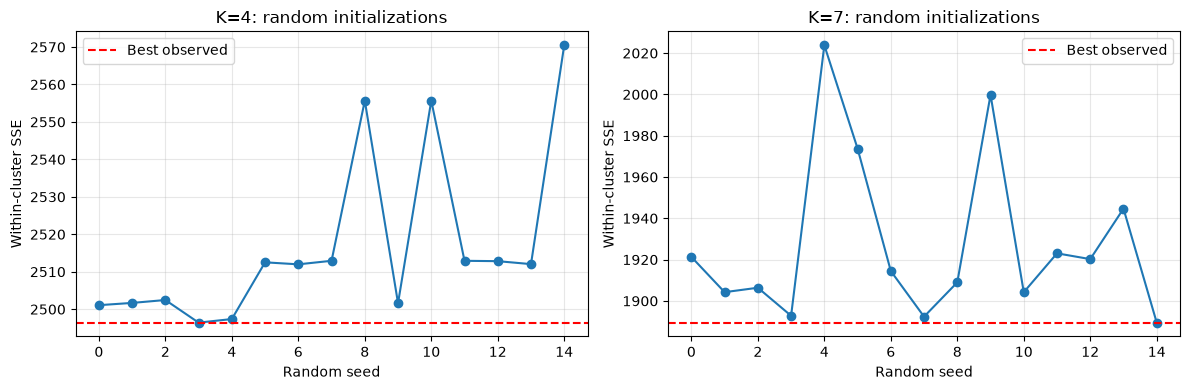

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, k in zip(axes, [4, 7]):
    subset = runs_df[runs_df['K'] == k]
    ax.plot(subset['Seed'], subset['Inertia'], 'o-')
    ax.axhline(best_models[k].inertia_, color='red', linestyle='--', label='Best observed')
    ax.set(title=f'K={k}: random initializations', xlabel='Random seed', ylabel='Within-cluster SSE')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Results of Random Initializations**

For **K=4**, the lowest observed objective is obtained with `random_state=3`: approximately **2496.421** (16 iterations). The 15 runs give values between 2496.421 and 2570.481 and fall into three groups of local optima: six runs at about 2496–2503 (seeds 0, 1, 2, 3, 4, 9), six at about 2512 (seeds 5, 6, 7, 11, 12, 13), and three at about 2556–2570 (seeds 8, 10, 14). Six runs end within 0.25% of the best value, so the solution is fairly stable.

For **K=7**, the best run uses `random_state=14`, with an objective of approximately **1889.485** (16 iterations). The values are more scattered, from 1889.485 to 2023.827 (a spread of about 7%), and only seeds 14, 7 (1892.373) and 3 (1892.807) are within 0.2% of the best. With more clusters there are more local optima, so the choice of the best of several runs matters more.

The standardized data scatter is 5000 (1000 observations × 5 features), so the selected partitions explain about **50.1%** (K=4) and **62.2%** (K=7) of it. The objective for K=7 is about 24.3% lower than for K=4, but a lower objective for K=7 alone does not establish a better partition: increasing the number of clusters always reduces within-cluster scatter. Interpretability also matters. The "best" runs are the best observed among 15, not a proof of the global optimum.

**Cluster Means and Relative Deviations**

For each selected partition, we compare cluster means with overall means **in original units**:

$$d_{cj}=100\frac{\bar{x}_{cj}-\bar{x}_j}{\bar{x}_j}.$$

In [7]:
labels_by_k = {}
cluster_means = {}
relative_deviations = {}
profiles = {}

for k in [4, 7]:
    old_labels = best_models[k].labels_
    order = X.groupby(old_labels)['energy'].mean().sort_values().index
    labels = old_labels.copy()
    
    for new_number, old_number in enumerate(order, start=1):
        labels[old_labels == old_number] = new_number
    
    labels_by_k[k] = labels

    means = X.groupby(labels).mean()
    means.index.name = 'Cluster'
    
    sizes = X.groupby(labels).size()
    deviations = 100 * (means - overall_means) / overall_means
    
    cluster_means[k] = means
    relative_deviations[k] = deviations.copy()

    profiles[k] = means.copy()
    profiles[k]['Size'] = sizes
    profiles[k]['Share (%)'] = 100 * sizes / len(X)

    print(f"K={k}: cluster means and sizes")
    display(profiles[k].round(2))
    
    deviations['Size'] = sizes
    deviations['Share (%)'] = 100 * sizes / len(X)

    print("Deviations from overall means (%)")
    display(deviations.round(1))

K=4: cluster means and sizes


,danceability,energy,valence,acousticness,tempo,Size,Share (%)
Cluster,,,,,,,
1,0.52,0.40,0.34,0.71,111.60,253,25.3
2,0.63,0.65,0.37,0.21,102.51,235,23.5
3,0.61,0.66,0.60,0.27,162.35,241,24.1
4,0.75,0.72,0.70,0.18,108.77,271,27.1


Deviations from overall means (%)


,danceability,energy,valence,acousticness,tempo,Size,Share (%)
Cluster,,,,,,,
1,-17.3,-34.1,-33.5,106.2,-7.7,253,25.3
2,0.6,7.6,-26.1,-38.3,-15.2,235,23.5
3,-3.4,8.3,18.4,-20.6,34.3,241,24.1
4,18.6,17.9,37.5,-47.5,-10.1,271,27.1


K=7: cluster means and sizes


,danceability,energy,valence,acousticness,tempo,Size,Share (%)
Cluster,,,,,,,
1,0.43,0.35,0.30,0.75,91.48,102,10.2
2,0.67,0.45,0.42,0.63,110.17,155,15.5
3,0.44,0.52,0.33,0.51,153.79,92,9.2
4,0.78,0.60,0.63,0.20,103.00,143,14.3
5,0.64,0.68,0.66,0.24,162.39,197,19.7
6,0.61,0.68,0.35,0.14,106.27,173,17.3
7,0.71,0.83,0.71,0.16,110.63,138,13.8


Deviations from overall means (%)


,danceability,energy,valence,acousticness,tempo,Size,Share (%)
Cluster,,,,,,,
1,-32.0,-41.5,-40.7,119.3,-24.4,102,10.2
2,6.7,-26.0,-16.5,82.7,-8.9,155,15.5
3,-30.7,-14.0,-34.5,49.2,27.2,92,9.2
4,24.2,-1.3,24.1,-42.1,-14.8,143,14.3
5,2.1,12.1,30.3,-30.8,34.3,197,19.7
6,-3.2,12.7,-30.0,-58.4,-12.1,173,17.3
7,12.5,37.4,40.9,-53.1,-8.5,138,13.8


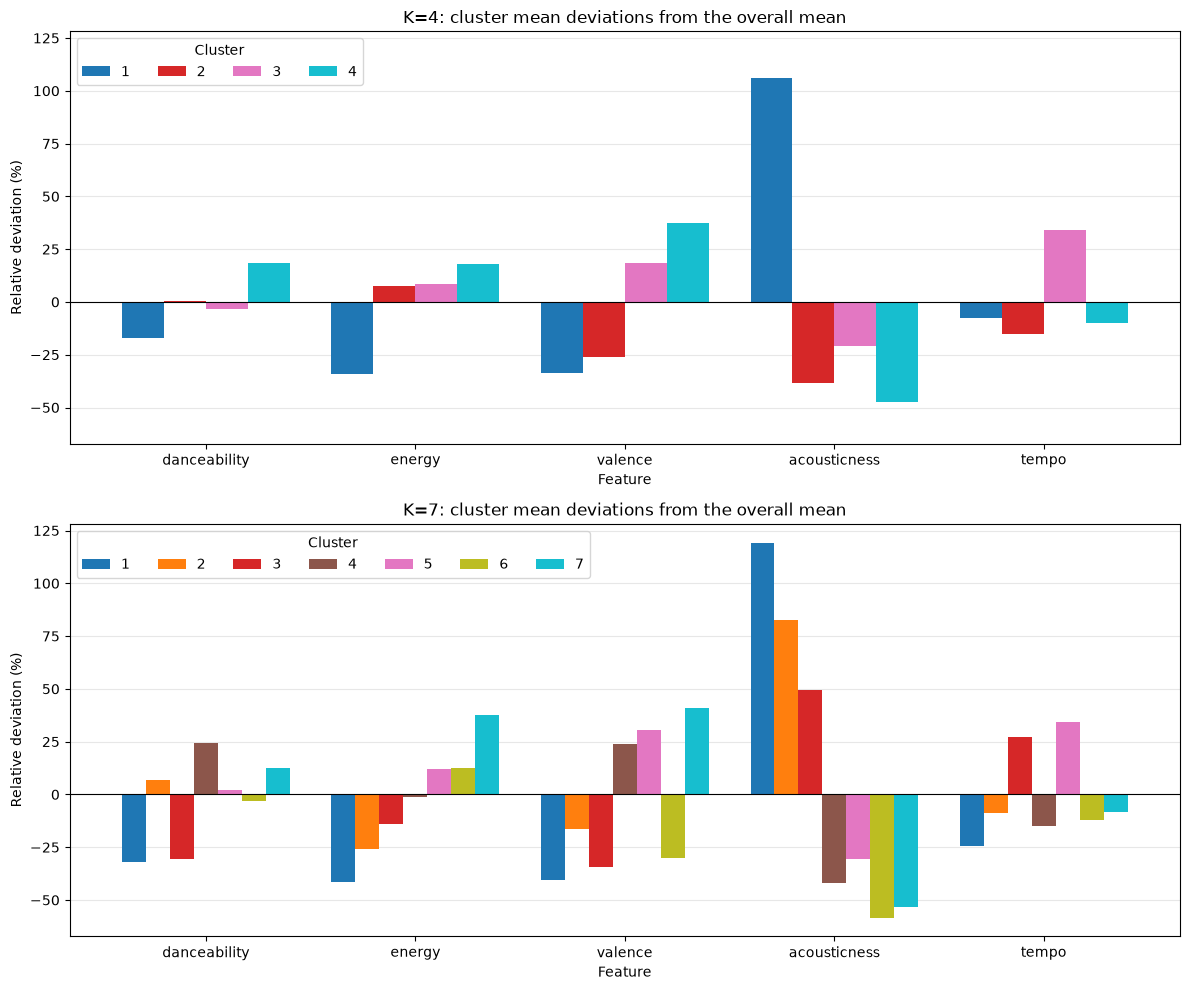

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharey=True)

for ax, k in zip(axes, [4, 7]):
    relative_deviations[k].T.plot.bar(ax=ax, width=0.8, colormap='tab10', rot=0)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set(title=f'K={k}: cluster mean deviations from the overall mean',
           xlabel='Feature', 
           ylabel='Relative deviation (%)')
    ax.legend(title='Cluster', ncol=k, loc='upper left')
    ax.grid(True, axis='y', alpha=0.3)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Interpretation of K=4**

Overall means: danceability 0.630, energy 0.606, valence 0.506, acousticness 0.344, tempo 120.9 bpm. Clusters are numbered by increasing mean energy.

| Cluster | Size | Share | Interpretation relative to the full dataset |
|---|---:|---:|---|
| 1 | 253 | 25.30% | **Mellow acoustic tracks:** acousticness **+106.2%** (0.71 vs 0.34), energy **−34.1%**, valence **−33.5%**, and danceability −17.3%. Tempo is slightly lower (−7.7%). |
| 2 | 235 | 23.50% | **Energetic, electronic, darker-mood tracks:** valence **−26.1%**, acousticness **−38.3%** and a slower tempo (−15.2%, about 103 bpm). Energy is slightly above average (+7.6%); danceability is near average (+0.6%). |
| 3 | 241 | 24.10% | **Fast upbeat tracks:** tempo **+34.3%** (about 162 bpm) and valence +18.4%, with acousticness −20.6% and energy +8.3%. Danceability is near average (−3.4%). |
| 4 | 271 | 27.10% | **Danceable, happy, energetic tracks:** valence **+37.5%**, danceability **+18.6%**, energy **+17.9%**, with the lowest acousticness (**−47.5%**). Tempo is slightly lower (−10.1%). |


**Interpretation of K=7**

Clusters are numbered by increasing mean energy.

| Cluster | Size | Share | Interpretation relative to the full dataset |
|---|---:|---:|---|
| 1 | 102 | 10.20% | **Slow, quiet, sad acoustic tracks:** acousticness **+119.3%**, energy **−41.5%**, valence **−40.7%**, danceability −32.0% and tempo −24.4% (about 91 bpm). |
| 2 | 155 | 15.50% | **Danceable acoustic-leaning tracks:** acousticness **+82.7%**, energy −26.0% and valence −16.5%; danceability is slightly above average (+6.7%) and tempo is slightly lower (−8.9%). |
| 3 | 92 | 9.20% | **Fast, non-danceable, dark semi-acoustic tracks:** tempo **+27.2%** (about 154 bpm), danceability **−30.7%**, valence **−34.5%**, acousticness +49.2%, and energy −14.0%. |
| 4 | 143 | 14.30% | **Danceable, cheerful, electronic mid-tempo tracks:** danceability **+24.2%**, valence **+24.1%**, acousticness **−42.1%**, and tempo −14.8%. Energy is near average (−1.3%). |
| 5 | 197 | 19.70% | **Fast upbeat tracks:** tempo **+34.3%** (about 162 bpm), valence **+30.3%**, energy +12.1%, acousticness −30.8%. Danceability is near average (+2.1%). |
| 6 | 173 | 17.30% | **Energetic, electronic, dark-mood tracks:** acousticness **−58.4%**, valence **−30.0%**, energy +12.7%, tempo −12.1%. Danceability is near average (−3.2%). |
| 7 | 138 | 13.80% | **The most energetic and happiest tracks:** energy **+37.4%**, valence **+40.9%**, danceability +12.5%, acousticness **−53.1%**, and tempo −8.5%. |

Most K=7 clusters are refinements of the K=4 clusters: K=7 clusters 1, 2 and 3 come mostly from K=4 cluster 1 (acoustic), cluster 5 corresponds to K=4 cluster 3 (fast upbeat), cluster 6 to K=4 cluster 2 (electronic, dark mood), and clusters 4 and 7 come mostly from K=4 cluster 4 (danceable and happy).

- **K=4** produces four clearly different profiles, each with two or three dominant deviations (about ±30% or more) that can be named directly: mellow acoustic, energetic electronic with a darker mood, fast and upbeat, and danceable and happy. The clusters are of similar size (23.5–27.1%).
- **K=7** gives a more detailed partition (62.2% of the scatter explained against 50.1%), but several clusters differ only in the strength of the same traits: clusters 4 and 7 are both danceable, cheerful and electronic and differ mainly in energy (−1.3% vs +37.4%), and clusters 5 and 6 repeat the K=4 profiles almost unchanged. Three clusters (1, 2, 3) split the acoustic group, with some subtle differences. Several clusters are small (9.2–15.5%).

**K=4 is preferable for interpretation**, as it identifies four distinct, concisely describable groups of tracks and each can be summarized in one sentence.

K=7 does give useful extra detail, mainly the split of acoustic tracks into slow and sad (cluster 1), danceable (cluster 2) and fast and dark (cluster 3), but this makes the overall interpretation less concise. If a finer analysis of the acoustic tracks is needed, K=7 is the better choice; for a general description of the pop tracks, K=4 is enough.
